# 01 · Data Exploration

**Goal:** understand the raw hotel bookings dataset before cleaning it.

**Input:** `data/hotel_bookings.csv` · **Target:** `is_canceled` (1 = booking was cancelled)

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

## 1. Load the data

In [2]:
df = pd.read_csv("../data/hotel_bookings.csv")
print("Shape:", df.shape)
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 2. Structure and missing values

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [4]:
missing = df.isnull().sum()
missing[missing > 0].sort_values(ascending=False)

company     112593
agent        16340
country        488
children         4
dtype: int64

## 3. Target balance

is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


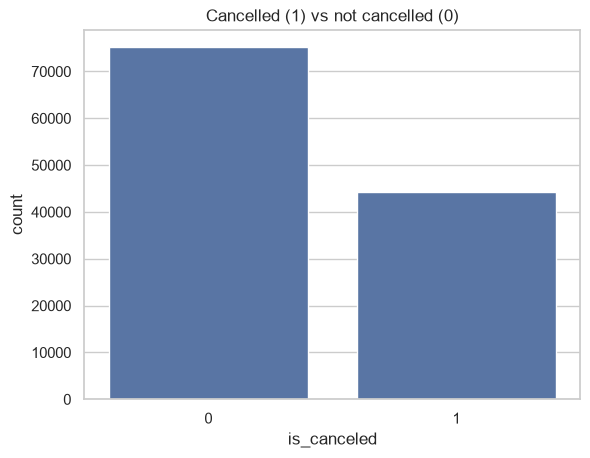

In [5]:
print(df["is_canceled"].value_counts(normalize=True).round(3))
sns.countplot(data=df, x="is_canceled")
plt.title("Cancelled (1) vs not cancelled (0)")
plt.show()

## 4. Cancellation rate by key categories

In [6]:
for col in ["hotel", "deposit_type", "market_segment", "customer_type"]:
    print(df.groupby(col)["is_canceled"].mean().round(3).sort_values(ascending=False), "\n")

hotel
City Hotel      0.417
Resort Hotel    0.278
Name: is_canceled, dtype: float64 

deposit_type
Non Refund    0.994
No Deposit    0.284
Refundable    0.222
Name: is_canceled, dtype: float64 

market_segment
Undefined        1.000
Groups           0.611
Online TA        0.367
Offline TA/TO    0.343
Aviation         0.219
Corporate        0.187
Direct           0.153
Complementary    0.131
Name: is_canceled, dtype: float64 

customer_type
Transient          0.407
Contract           0.310
Transient-Party    0.254
Group              0.102
Name: is_canceled, dtype: float64 



## 5. Lead time vs cancellation

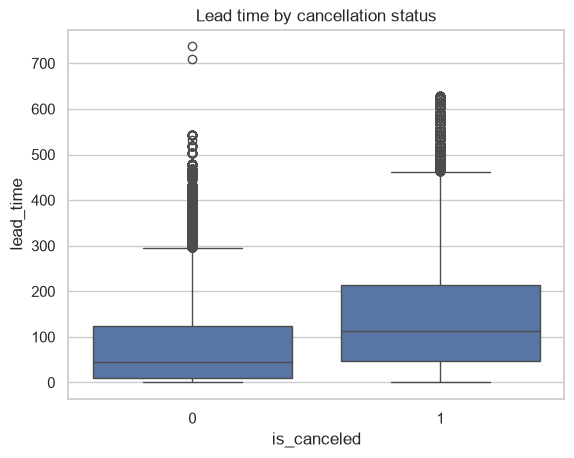

In [7]:
sns.boxplot(data=df, x="is_canceled", y="lead_time")
plt.title("Lead time by cancellation status")
plt.show()